In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Building Dataframe #


In [ ]:
# reading csv files into dataframes
cat = pd.read_csv('SAMI_Input_Cat_Cluster/samiDR3InputCatClusters.csv')
print('Sample Size of SAMI Input Catalogue Dataset:', len(cat))
print(cat.columns)
    # "Mstar","dex","Logarithm of stellar mass","phys.mass"

kin = pd.read_csv('SAMI_Kinematics/samiDR3StelKin.csv')
print('Sample Size of SAMI Stellar Kinematics Dataset:', len(kin))
print(kin.columns)
    # "SIGMA_RE","km/s","Velocity dispersion from Re Sersic aperture spectra","phys.veloc.dispersion"

morph = pd.read_csv('SAMI_Visual_Morphology/samiDR3VisualMorphology.csv')
print('Sample Size of SAMI Visual Morphology Dataset:', len(morph))
print(morph.columns)
    # "TYPE","none","Morphological Type 

Sample Size of SAMI Input Catalogue Dataset: 1433
Index(['Unnamed: 0', 'catid', 'ra_obj', 'dec_obj', 'r_petro', 'r_auto',
       'z_spec', 'm_r', 'r_e', 'mu_within_1re', 'mu_1re', 'mu_2re', 'ellip',
       'pa', 'g_i', 'mstar', 'r_on_rtwo', 'v_on_sigma', 'is_mem', 'surv_sami',
       'bad_class'],
      dtype='object')
Sample Size of SAMI Stellar Kinematics Dataset: 3426
Index(['Unnamed: 0', 'cubeid', 'cubeidpub', 'cubename', 'catid', 'pa_stelkin',
       'pa_stelkin_err', 'sigma_re', 'sigma_re_err', 'sigma_3kpc_round',
       'sigma_3kpc_round_err', 'sigma_1_4_arcsecond',
       'sigma_1_4_arcsecond_err', 'sigma_2_arcsecond', 'sigma_2_arcsecond_err',
       'sigma_3_arcsecond', 'sigma_3_arcsecond_err', 'sigma_4_arcsecond',
       'sigma_4_arcsecond_err', 'aper_corr_flag', 'rmax_aper_corr',
       'lambdar_re', 'lambdar_re_err', 'lambdar_max', 'lambdar_max_err',
       'vsigma_re', 'vsigma_re_err', 'vsigma_max', 'vsigma_max_err',
       'mean_k51_re', 'mean_k51_re_err', 'sigma_re_mge',

In [6]:
mass = cat[['catid', 'mstar']]
print('Sample Size of Mass Dataset:', mass)
vdisp = kin[['catid', 'sigma_re']]
print('Sample Size of Velocity Dispersion Dataset:', vdisp)
type = morph[['catid', 'type']]
print('Sample Size of Morphology Dataset:', type)

Sample Size of Mass Dataset:            catid      mstar
0     9011900001  11.587700
1     9011900002  10.157130
2     9011900003  10.205531
3     9011900005   9.887663
4     9011900006  10.841409
...          ...        ...
1428  9403802507  10.861442
1429  9403802643  11.135397
1430  9403802645  10.923486
1431  9403802684   9.989643
1432  9403802714  10.731458

[1433 rows x 2 columns]
Sample Size of Velocity Dispersion Dataset:            catid    sigma_re
0           6821         NaN
1           6837         NaN
2           7139  235.612810
3           7206  106.101770
4           7289  205.145280
...          ...         ...
3421  9403801268         NaN
3422  9403801272         NaN
3423  9403801281   57.441160
3424  9403801368         NaN
3425  9403801579   52.304882

[3426 rows x 2 columns]
Sample Size of Morphology Dataset:            catid  type
0           6821   3.0
1           6837   3.0
2           7139   1.0
3           7206   2.0
4           7289   0.5
...          ...   .

In [7]:
morphcat = pd.merge(morph, mass, on='catid', how='inner')
df = pd.merge(morphcat, vdisp, on='catid', how='inner')
print('Final Data Set', len(df))
print(df.head(20))

Final Data Set 962
    Unnamed: 0       catid  type      mstar    sigma_re
0         2151  9008500001   0.0  11.733240         NaN
1         2152  9008500002   0.0  11.733201         NaN
2         2153  9008500004   1.5  10.639072         NaN
3         2154  9008500007   0.0  10.939993  265.057370
4         2154  9008500007   0.0  10.939993         NaN
5         2155  9008500018   0.5  10.028619  130.505040
6         2156  9008500020   0.0  10.894950  170.477860
7         2157  9008500022   0.5  10.140078   98.179590
8         2158  9008500024   0.5  10.753547  187.108870
9         2159  9008500034   1.0  10.199323  143.926180
10        2160  9008500042   0.0  10.522638  202.322860
11        2161  9008500043   3.0   9.631680   53.505527
12        2162  9008500059   0.0  10.612209  204.846340
13        2163  9008500062   2.0  10.627398  150.148380
14        2164  9008500064   0.0  10.014470  125.197975
15        2165  9008500067   1.0  10.620266  186.697370
16        2166  9008500068   

In [ ]:
elliptical = df[df['type'] == 0.0] # choosing only elliptical galaxies
# key defines elliptical galaxies as having the type = 0
    # 0.5 is for galaxies between elliptical and lenticular stages

print('Number of Elliptical Galaxies:', len(elliptical))
print('Elliptical Galaxies:', elliptical.head(20))

# Columns are just misaligned, there are mstar and sigma_re values

Number of Elliptical Galaxies: 152
Elliptical Galaxies:     Unnamed: 0       catid  type      mstar    sigma_re
0         2151  9008500001   0.0  11.733240         NaN
1         2152  9008500002   0.0  11.733201         NaN
3         2154  9008500007   0.0  10.939993  265.057370
4         2154  9008500007   0.0  10.939993         NaN
6         2156  9008500020   0.0  10.894950  170.477860
10        2160  9008500042   0.0  10.522638  202.322860
12        2162  9008500059   0.0  10.612209  204.846340
14        2164  9008500064   0.0  10.014470  125.197975
16        2166  9008500068   0.0  10.189114   87.443590
20        2170  9008500077   0.0  10.764045  183.164600
27        2177  9008500096   0.0  10.905760  164.250000
34        2184  9008500114   0.0  11.131812         NaN
36        2186  9008500118   0.0  10.358594  122.640700
44        2194  9008500138   0.0  10.378108  114.042900
45        2195  9008500139   0.0  10.479002  131.962300
47        2197  9008500145   0.0  10.368532     

# Cleaning Data #

In [10]:
df_clean_elliptical = elliptical.dropna(subset = ['mstar', 'sigma_re'])

print('Cleaned Data Set', len(df_clean_elliptical))
print(df_clean_elliptical.head(20))

Cleaned Data Set 107
     Unnamed: 0       catid  type      mstar    sigma_re
3          2154  9008500007   0.0  10.939993  265.057370
6          2156  9008500020   0.0  10.894950  170.477860
10         2160  9008500042   0.0  10.522638  202.322860
12         2162  9008500059   0.0  10.612209  204.846340
14         2164  9008500064   0.0  10.014470  125.197975
16         2166  9008500068   0.0  10.189114   87.443590
20         2170  9008500077   0.0  10.764045  183.164600
27         2177  9008500096   0.0  10.905760  164.250000
36         2186  9008500118   0.0  10.358594  122.640700
44         2194  9008500138   0.0  10.378108  114.042900
45         2195  9008500139   0.0  10.479002  131.962300
52         2202  9008500169   0.0  10.709361  173.848070
57         2207  9008500182   0.0  10.435489  166.522140
71         2221  9008500225   0.0  10.922438  232.152270
74         2224  9008500234   0.0  10.911675  213.418180
92         2240  9008500303   0.0  10.750400  187.230400
93        

# Plotting Mass against Velocity Dispersion #

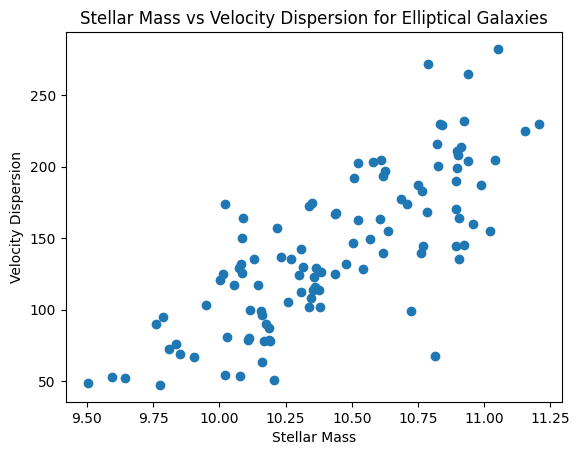

In [11]:
plt.scatter(df_clean_elliptical['mstar'], df_clean_elliptical['sigma_re'])
plt.title('Stellar Mass vs Velocity Dispersion for Elliptical Galaxies')
plt.xlabel('Stellar Mass')
plt.ylabel('Velocity Dispersion')
plt.show()